# Jordan — the strength model

Part 1 of the project, written out in full. Jordan's results improved sharply
from around mid-2022. Before asking *why*, this notebook establishes **what the
strength model actually does**, so every later claim rests on something inspected
rather than assumed.

1. **The model** — every step, from raw scorelines to a strength number with an interval
2. **The divergence** — why raw results and the model disagree about 2026
3. **The placebo** — is the rise Jordan's, or did the whole region improve?
4. **Coverage** — what the squad data rests on, before any of it is used

The composition analysis is deliberately not here yet.

```
cd JordanData
python trajectory.py     # the trace
python uncertainty.py    # bootstrap intervals (~30 min)
```

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "JordanData"))

import viz
viz.use_style()

from data import load_results, index_teams, team_view
from baseline import PoissonStrength
from trajectory import build_arrays

OUT = ROOT / "outputs"

df = load_results()
teams, idx = index_teams(df)
ti = idx["Jordan"]
strength = pd.read_csv(OUT / "jordan_strength_ci.csv", parse_dates=["date"])
trace = pd.read_csv(OUT / "jordan_strength_trace.csv", parse_dates=["date"])

print(f"{len(df):,} international matches, {df.date.min():%Y} to {df.date.max():%Y}")
print(f"{len(teams)} teams -> {2 * len(teams) + 1} parameters per fit")

49,547 international matches, 1872 to 2026
337 teams -> 675 parameters per fit


## 1. The model

### 1.1 What it assumes

Every team carries two numbers: an **attack** rating and a **defence** rating.
Goals are Poisson, and the rate each side scores at is set by the gap between one
team's attack and the other's defence:

$$\mu_{\text{home}} = \exp(\text{atk}_h - \text{def}_a + \gamma)
\qquad
\mu_{\text{away}} = \exp(\text{atk}_a - \text{def}_h)$$

$\gamma$ is a single global home-advantage term, added only when the match is not
on neutral ground. One number shared by every team, not one per team. Jordan plays
161 of its 488 matches on neutral ground, so this matters here.

This is Dixon & Coles (1997) with the time-decay term, after Maher (1982). The
Dixon–Coles low-score correlation correction is **not** included: the two
scorelines are treated as conditionally independent given the rates.

### 1.2 Recent matches count more

Each match is weighted by its age at the reference date, halving every 730 days:

$$w = 0.5^{\,\text{days before}\,/\,730}$$

This is the most consequential setting in the model — it decides how much history
is allowed to speak.

findfont: Failed to find font weight semibold, now using 700.


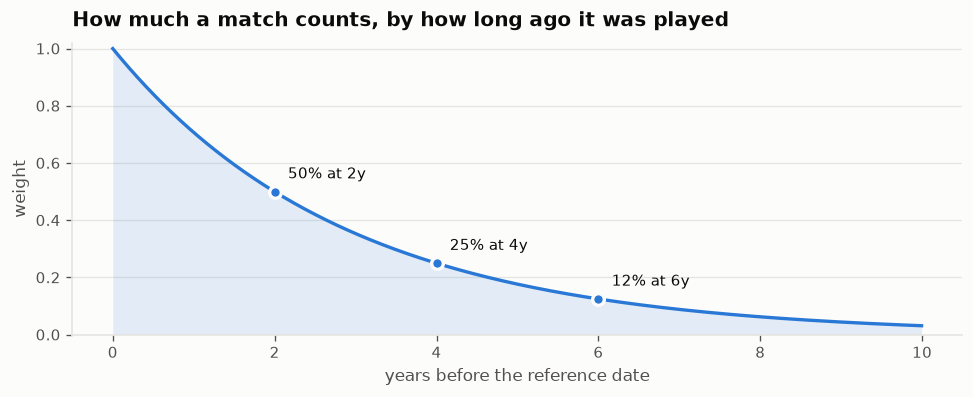

In [2]:
days = np.arange(0, 3651)
w = 0.5 ** (days / 730.0)

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(days / 365.25, w, color=viz.BLUE)
ax.fill_between(days / 365.25, 0, w, color=viz.BLUE, alpha=0.12, linewidth=0)
viz.despine(ax)
ax.set_title("How much a match counts, by how long ago it was played")
ax.set_xlabel("years before the reference date")
ax.set_ylabel("weight")
ax.set_ylim(0, 1.02)

for yrs in (2, 4, 6):
    val = 0.5 ** (yrs * 365.25 / 730.0)
    ax.plot([yrs], [val], "o", color=viz.BLUE, markersize=7,
            markeredgecolor=viz.SURFACE, markeredgewidth=2, zorder=3)
    ax.annotate(f"{val:.0%} at {yrs}y", xy=(yrs, val), xytext=(8, 8),
                textcoords="offset points", fontsize=9, color=viz.INK)
plt.show()

So the ten-year lookback window is misleading about how much data really speaks. A
match from nine years ago carries under 2% of the weight of one played today. The
**effective** sample is far smaller than the raw count:

In [3]:
rows = []
for ref in pd.to_datetime(["2015-01-01", "2019-01-01", "2022-07-01", "2026-01-01"]):
    h, a, gh, ga, flag, dd, n, win = build_arrays(df, idx, ref)
    wts = 0.5 ** (dd / 730.0)
    jor = ((win.home_team == "Jordan") | (win.away_team == "Jordan")).to_numpy()
    rows.append({
        "reference date": ref.date(),
        "matches in window": n,
        "effective n": round(wts.sum(), 1),
        "Jordan matches": int(jor.sum()),
        "Jordan effective n": round(wts[jor].sum(), 1),
    })
pd.DataFrame(rows)

,reference date,matches in window,effective n,Jordan matches,Jordan effective n
0,2015-01-01,9488,2693.3,143,47.1
1,2019-01-01,9559,2684.0,147,39.2
2,2022-07-01,9411,2728.2,145,38.9
3,2026-01-01,9640,2945.9,132,43.4


That last column is the honest sample size behind Jordan's rating: roughly
**20–25 matches**, not 130. It is why every interval in this project is wide, and
why "no claim without an interval" is a rule rather than a preference.

### 1.3 The penalty, and what it buys

The likelihood alone cannot identify the model: add a constant to every attack and
subtract it from every defence and all predictions are unchanged. An L2 penalty on
the attack and defence vectors pins them down:

$$\text{objective} = \ell(\theta) - \lambda\Big(\textstyle\sum_i \text{atk}_i^2 + \sum_i \text{def}_i^2\Big), \qquad \lambda = 0.05$$

It does a second job at the same time. A team with three matches on record is
pulled toward the global mean rather than handed an extreme rating on almost no
evidence — partial pooling in all but name, the frequentist stand-in for the
hierarchical prior a Bayesian version would use. $\gamma$ is left unpenalised.

### 1.4 Fitting, and no peeking

675 parameters at once — 337 attacks, 337 defences, one home advantage — by
L-BFGS-B with an analytic gradient, so no numerical differentiation. About 0.1s
per fit.

The trace refits from scratch every six months, each fit seeing **only matches
strictly before its reference date**. The curve is one you could have drawn on the
day, not a retrospective smoothing.

In [4]:
ref = pd.Timestamp("2026-01-01")
h, a, gh, ga, flag, dd, n, win = build_arrays(df, idx, ref)
m = PoissonStrength(len(teams)).fit(h, a, gh, ga, flag, dd)

print(f"fit at {ref.date()} on {n:,} matches, nothing after that date")
print(f"converged: {m.converged}\n")
print(f"  attack   {m.atk[ti]:+.3f}  -> scores  exp({m.atk[ti]:+.3f})  = "
      f"{np.exp(m.atk[ti]):.2f} vs an average defence")
print(f"  defence  {m.dfn[ti]:+.3f}  -> concedes exp({-m.dfn[ti]:+.3f}) = "
      f"{np.exp(-m.dfn[ti]):.2f} vs an average attack")
print(f"  gamma    {m.adv:+.3f}  -> x{np.exp(m.adv):.2f} to the home rate")
print(f"\n  strength = {np.exp(m.atk[ti]):.2f} - {np.exp(-m.dfn[ti]):.2f} "
      f"= {m.strength(ti):+.3f}")

fit at 2026-01-01 on 9,640 matches, nothing after that date
converged: True

  attack   +0.706  -> scores  exp(+0.706)  = 2.03 vs an average defence
  defence  +0.410  -> concedes exp(-0.410) = 0.66 vs an average attack
  gamma    +0.241  -> x1.27 to the home rate

  strength = 2.03 - 0.66 = +1.363


### 1.5 What "strength" means

$$\text{strength}_i = e^{\text{atk}_i} - e^{-\text{def}_i}$$

Set the opponent to an average team — attack and defence both 0 — on neutral
ground. The team then scores $e^{\text{atk}_i}$ and concedes $e^{-\text{def}_i}$,
and the difference is the **expected goal difference against an average
international team on neutral ground**. Jordan at 1.36 means "would beat a generic
average side by about 1.4 goals".

### 1.6 A worked prediction

The model never sees a fixture list — it produces rates for any pairing. Here is
what it expected of Jordan's 2026 matches, fit on data up to the start of 2026,
against what actually happened.

In [5]:
played = team_view(df, "Jordan")
played = played[played.date >= "2026-01-01"]

rows = []
for _, r in played.iterrows():
    oi = idx[r.opponent]
    if r.venue == "away":      # opponent is home, so they get gamma
        mo, mj = m.rates(np.array([oi]), np.array([ti]), np.array([1.0]))
    else:
        flag_ = np.array([1.0 if r.venue == "home" else 0.0])
        mj, mo = m.rates(np.array([ti]), np.array([oi]), flag_)
    rows.append({
        "date": r.date.date(), "opponent": r.opponent, "venue": r.venue,
        "expected": f"{mj[0]:.2f} - {mo[0]:.2f}",
        "actual": f"{int(r.gf)} - {int(r.ga)}",
        "expected GD": round(float(mj[0] - mo[0]), 2),
        "actual GD": int(r.gd),
    })
pd.DataFrame(rows)

,date,opponent,venue,expected,actual,expected GD,actual GD
0,2026-03-27,Costa Rica,neutral,1.25 - 1.21,2 - 2,0.03,0
1,2026-03-31,Nigeria,neutral,1.23 - 1.48,2 - 2,-0.25,0
2,2026-05-31,Switzerland,away,0.77 - 2.84,1 - 4,-2.07,-3
3,2026-06-07,Colombia,neutral,0.58 - 2.77,0 - 2,-2.19,-2
4,2026-06-16,Austria,neutral,0.79 - 1.85,1 - 3,-1.06,-2
5,2026-06-22,Algeria,neutral,0.99 - 1.85,1 - 2,-0.86,-1
6,2026-06-27,Argentina,neutral,0.38 - 2.76,1 - 3,-2.39,-2


Jordan lost every one of these — and the model *expected* them to lose most.
Losing 1–3 to Argentina is close to par and is scored as such. That is opponent
adjustment doing its job, and it sets up section 2.

### 1.7 Where the uncertainty comes from

A point estimate on ~20 effective matches is not a finding. Intervals come from
500 bootstrap draws. Each draw resamples the **full 49k-match dataset with
replacement once**, then re-runs the entire trace on that resample.

Resampling once per draw rather than once per reference date is what makes the
draws **paired across dates**: draw *b* yields a whole trajectory, so a difference
between two dates can be read off draw by draw and gets an interval of its own.
Resampling independently per date would destroy that and leave every difference
uninterpretable.

Nonparametric on purpose. Simulating goals from the fitted Poisson would hold the
fixture list fixed and propagate only scoring noise; resampling matches also
propagates *which matches happened*, which for a team playing 15 a year is the
larger source of uncertainty.

findfont: Failed to find font weight semibold, now using 700.


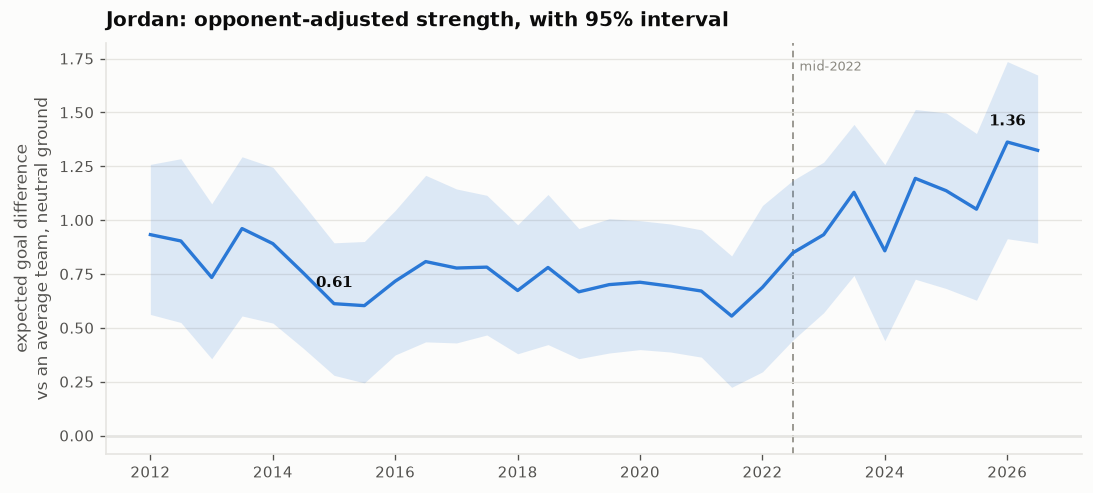

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.fill_between(strength.date, strength.strength_lo, strength.strength_hi,
                color=viz.BLUE, alpha=0.15, linewidth=0)
ax.plot(strength.date, strength.strength, color=viz.BLUE)
viz.mark_split(ax)
viz.despine(ax)
ax.axhline(0, color=viz.INK_MUTED, linewidth=0.8, zorder=0)
ax.set_title("Jordan: opponent-adjusted strength, with 95% interval")
ax.set_ylabel("expected goal difference\nvs an average team, neutral ground")

for when in ("2015-01-01", "2026-01-01"):
    r = strength.loc[strength.date == when].iloc[0]
    ax.annotate(f"{r.strength:.2f}", xy=(r.date, r.strength), xytext=(0, 10),
                textcoords="offset points", ha="center", fontsize=9,
                color=viz.INK, fontweight="semibold")
plt.show()

The rise is real: **+0.717, 95% CI [+0.203, +1.220]** from 2015 to 2026.

The interval also settles what *cannot* be said. 2026 is the highest point
estimate but is not separable from its neighbours — 2026 vs 2023 is +0.411, CI
[−0.031, +0.867]. "At the top of the range" is supportable; "the peak" is not.

### 1.8 Attack and defence separately

Both are log-scale parameters on the same footing, so they share an axis. Higher
defence is *better* — it enters the opponent's rate negatively.

findfont: Failed to find font weight semibold, now using 700.


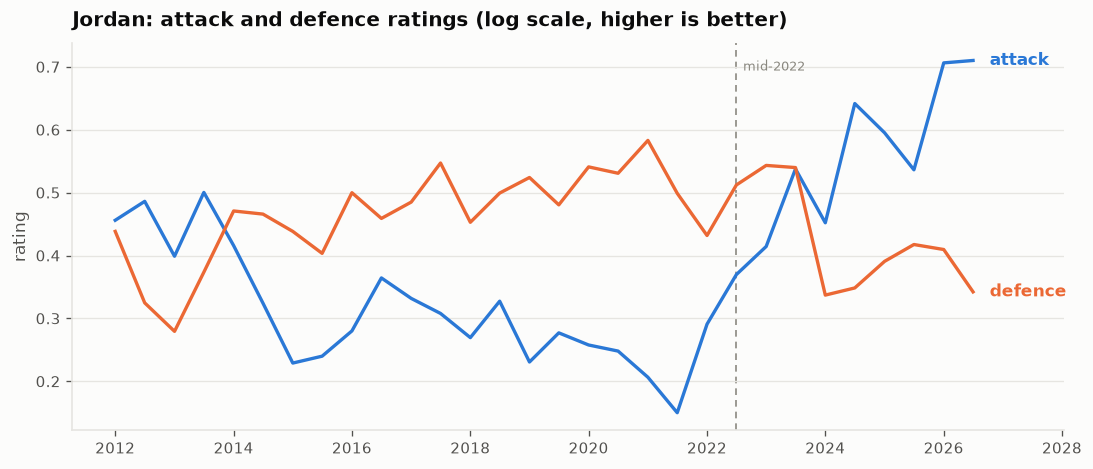

In [7]:
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(trace.date, trace.attack, color=viz.BLUE)
ax.plot(trace.date, trace.defence, color=viz.ORANGE)
viz.mark_split(ax); viz.despine(ax)
ax.set_title("Jordan: attack and defence ratings (log scale, higher is better)")
ax.set_ylabel("rating")
ax.set_xlim(right=trace.date.max() + pd.Timedelta(days=560))

last = trace.iloc[-1]
for col, colour in (("attack", viz.BLUE), ("defence", viz.ORANGE)):
    ax.annotate(col, xy=(last.date, last[col]), xytext=(10, 0),
                textcoords="offset points", va="center", fontsize=10,
                color=colour, fontweight="semibold")
plt.show()

Attack climbs from 0.23 to 0.71; defence sits roughly flat. Decomposing the rise
exactly —

$$\Delta\text{strength} = \underbrace{(e^{\text{atk}_1} - e^{\text{atk}_0})}_{\text{attacking}} + \underbrace{(e^{-\text{def}_0} - e^{-\text{def}_1})}_{\text{defensive}}$$

— and putting bootstrap intervals on each part:

| component | 2015→2026 | 95% CI | |
|---|---|---|---|
| attacking contribution | +0.744 | [+0.238, +1.212] | excludes 0 |
| defensive contribution | −0.027 | [−0.255, +0.196] | includes 0 |
| **attack minus defence** | **+0.771** | **[+0.229, +1.282]** | **excludes 0** |

The third row is the test that matters: it compares two uncertain quantities
rather than eyeballing two point estimates. An earlier version of this claim was
banned in `CLAUDE.md` for doing exactly the latter. It now holds.

### 1.9 One number that is not about Jordan

$\gamma$ is re-estimated at every refit, and it has been falling steadily across
the whole dataset. Worth knowing: a home win in 2026 is weaker evidence than a
home win in 2012.

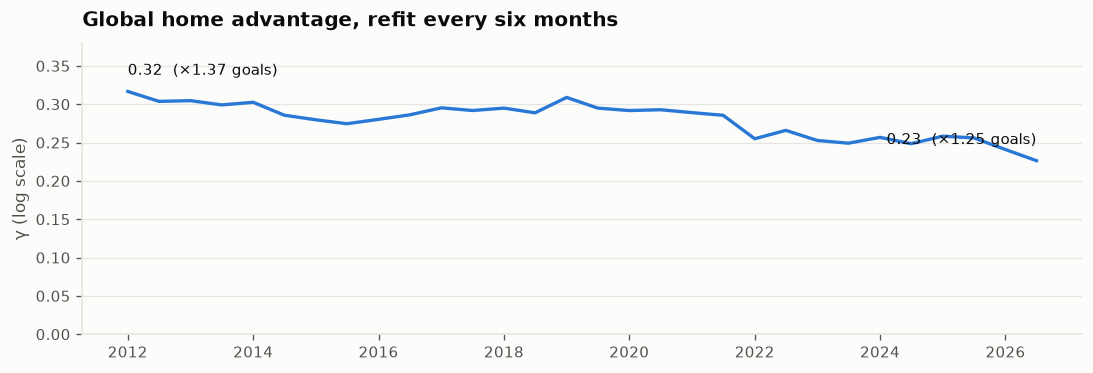

In [8]:
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(trace.date, trace.home_adv, color=viz.BLUE)
viz.despine(ax)
ax.set_title("Global home advantage, refit every six months")
ax.set_ylabel("γ (log scale)")
ax.set_ylim(0, trace.home_adv.max() * 1.2)

for i, ha in ((0, "left"), (len(trace) - 1, "right")):
    r = trace.iloc[i]
    ax.annotate(f"{r.home_adv:.2f}  (×{np.exp(r.home_adv):.2f} goals)",
                xy=(r.date, r.home_adv), xytext=(0, 10),
                textcoords="offset points", ha=ha, fontsize=9, color=viz.INK)
plt.show()

## 2. The divergence

2026 is simultaneously Jordan's **worst raw goal difference** and its **highest
strength estimate**. Both are correct: the opponents were Argentina, Austria,
Algeria, Switzerland and Colombia.

Two measures on different scales, so two panels sharing an x-axis — never two
y-axes on one plot.

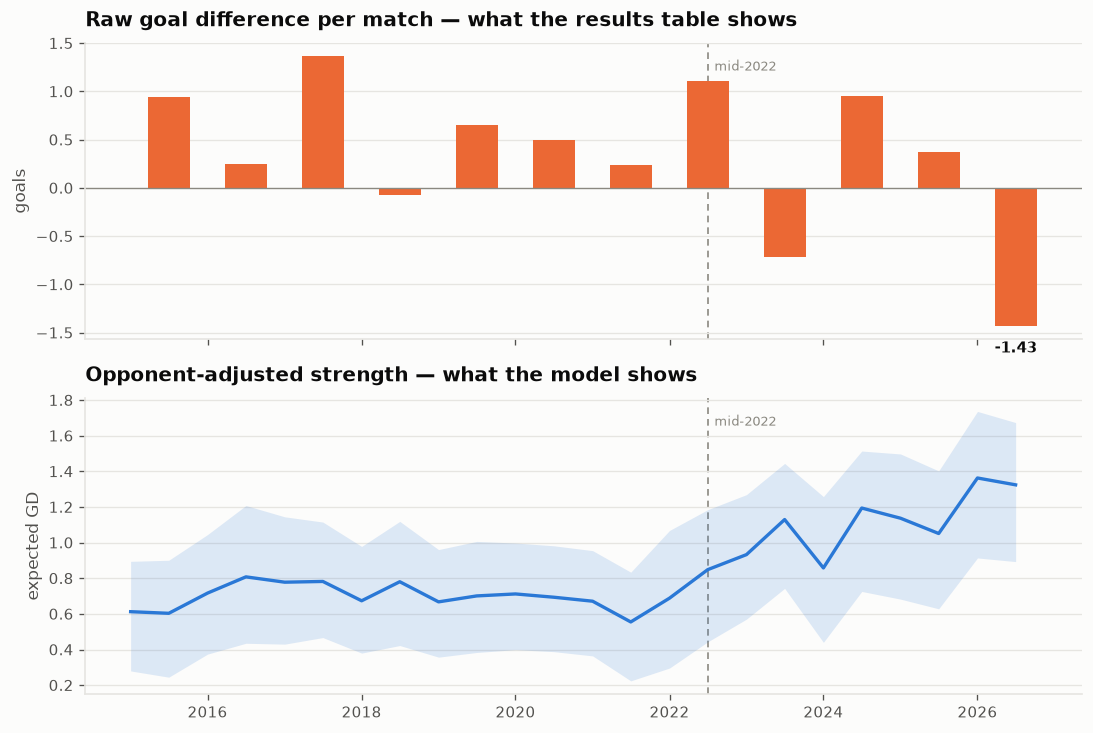

In [9]:
jor = team_view(df, "Jordan")
jor["year"] = jor.date.dt.year
raw = jor[jor.year.between(2015, 2026)].groupby("year").gd.mean().reset_index()
raw["date"] = pd.to_datetime(raw.year.astype(str) + "-07-01")

fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)

ax = axes[0]
ax.bar(raw.date, raw.gd, width=200, color=viz.ORANGE, zorder=2)
ax.axhline(0, color=viz.INK_MUTED, linewidth=0.8)
viz.despine(ax); viz.mark_split(ax)
ax.set_title("Raw goal difference per match — what the results table shows")
ax.set_ylabel("goals")
worst = raw.loc[raw.gd.idxmin()]
ax.annotate(f"{worst.gd:+.2f}", xy=(worst.date, worst.gd), xytext=(0, -16),
            textcoords="offset points", ha="center", fontsize=9,
            color=viz.INK, fontweight="semibold")

ax = axes[1]
s = strength[strength.date >= "2015-01-01"]
ax.fill_between(s.date, s.strength_lo, s.strength_hi, color=viz.BLUE,
                alpha=0.15, linewidth=0)
ax.plot(s.date, s.strength, color=viz.BLUE)
viz.despine(ax); viz.mark_split(ax)
ax.set_title("Opponent-adjusted strength — what the model shows")
ax.set_ylabel("expected GD")
plt.show()

This divergence is the project's headline, and it is the argument for building the
squad layer at all: if the raw table is misleading about *whether* Jordan
improved, it is worth asking what changed underneath.

## 3. Is the rise Jordan's, or the region's?

A rise only means something against a baseline. If every comparable AFC side
improved over the same years, there is nothing specific to explain.

**This costs no extra data.** The strength model reads scores, and
`data/results.csv` already holds every Iraq, Syria and UAE match. Nothing was
scraped for this section.

It also costs almost no extra compute. Every fit already estimates all 337
teams, so carrying three more through the bootstrap is bookkeeping. More
importantly, all four teams come from the **same resample** on each draw, so
the differences between them are paired and get real intervals — not two
separate intervals eyeballed against each other, which is the mistake the
attack/defence claim was originally banned for.

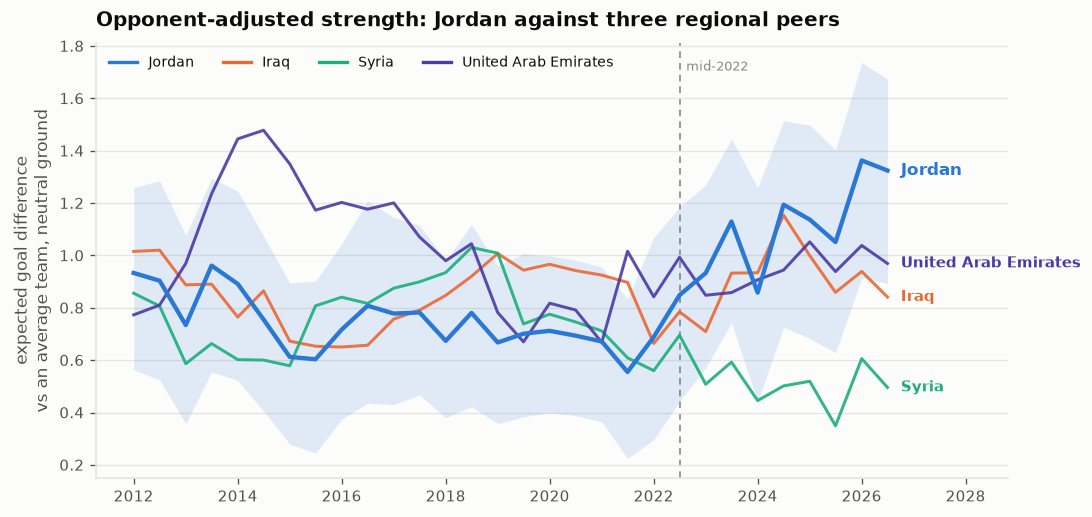

In [10]:
multi = pd.read_csv(OUT / "strength_ci_multi.csv", parse_dates=["date"])
PEERS = ["Iraq", "Syria", "United Arab Emirates"]

fig, ax = plt.subplots(figsize=(9, 4.2))

j = multi[multi.team == "Jordan"]
ax.fill_between(j.date, j.strength_lo, j.strength_hi, color=viz.BLUE,
                alpha=0.13, linewidth=0)
for name in PEERS:
    d = multi[multi.team == name]
    colour = viz.TEAM_COLOURS[name]
    ax.plot(d.date, d.strength, color=colour, linewidth=1.8, alpha=0.9)
    last = d.iloc[-1]
    ax.annotate(name, xy=(last.date, last.strength), xytext=(8, 0),
                textcoords="offset points", va="center", fontsize=9,
                color=colour, fontweight="semibold")
ax.plot(j.date, j.strength, color=viz.BLUE, linewidth=2.6, zorder=3)
last = j.iloc[-1]
ax.annotate("Jordan", xy=(last.date, last.strength), xytext=(8, 0),
            textcoords="offset points", va="center", fontsize=10,
            color=viz.BLUE, fontweight="semibold")

viz.mark_split(ax); viz.despine(ax)
ax.set_xlim(right=multi.date.max() + pd.Timedelta(days=850))
ax.set_title("Opponent-adjusted strength: Jordan against three regional peers")
ax.legend(handles=[plt.Line2D([], [], color=viz.TEAM_COLOURS[t], lw=2, label=t)
                   for t in ["Jordan"] + PEERS], loc="upper left", ncols=4,
          fontsize=8.5)
ax.set_ylabel("expected goal difference\nvs an average team, neutral ground")
plt.show()

Only Jordan's band is drawn, to keep the panel readable — the peers carry
intervals of similar width. The point is the shape: Jordan climbs, the other
three do not. Each side is directly labelled as well as coloured, so the lines
stay identifiable without relying on colour.

Note where UAE starts. In 2015 it is the strongest of the four by a distance,
and it declines from there.

In [11]:
cmp = pd.read_csv(OUT / "placebo_strength_comparison.csv")
cmp[cmp.kind == "change 2015->2026"][
    ["subject", "estimate", "lo", "hi", "excludes_zero"]].round(3)

,subject,estimate,lo,hi,excludes_zero
0,Jordan,0.717,0.203,1.220,True
1,Iraq,0.231,-0.195,0.664,False
2,Syria,0.002,-0.477,0.530,False
3,United Arab Emirates,-0.327,-0.811,0.152,False


**Jordan is the only one of the four whose rise is distinguishable from zero.**
Iraq improved somewhat, Syria not at all, UAE declined — and all three intervals
contain zero. Regional football did not uniformly improve.

The sharper test is the paired difference: Jordan's rise *minus* each peer's,
computed within each bootstrap draw.

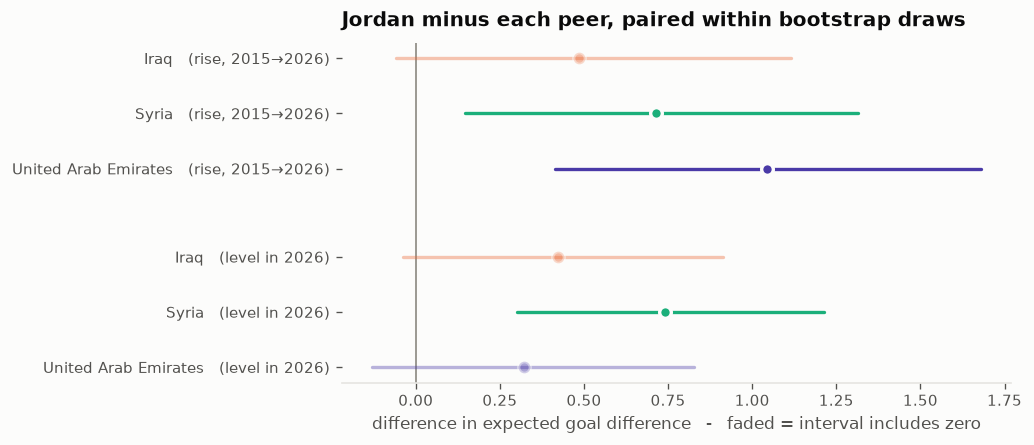

In [12]:
fig, ax = plt.subplots(figsize=(8.5, 3.6))
d = cmp[cmp.kind.isin(["rise vs peer", "2026 level vs peer"])].copy()
d["label"] = d.subject.str.replace("Jordan - ", "", regex=False)
# reversed: matplotlib stacks upward, and the rise is the primary claim
groups = [("2026 level vs peer", "level in 2026"), ("rise vs peer", "rise, 2015→2026")]

ypos, ticks, labels = 0, [], []
for kind, title in groups:
    sub = d[d.kind == kind].iloc[::-1]
    for _, r in sub.iterrows():
        solid = bool(r.excludes_zero)
        colour = viz.TEAM_COLOURS[r.label]
        ax.plot([r.lo, r.hi], [ypos, ypos], color=colour, linewidth=2,
                alpha=1.0 if solid else 0.38, solid_capstyle="round", zorder=2)
        ax.plot([r.estimate], [ypos], "o", color=colour, markersize=7, zorder=3,
                alpha=1.0 if solid else 0.45,
                markeredgecolor=viz.SURFACE, markeredgewidth=2)
        ticks.append(ypos); labels.append(f"{r.label}   ({title})")
        ypos += 1
    ypos += 0.6

ax.axvline(0, color=viz.INK_MUTED, linewidth=1.0, zorder=1)
ax.set_yticks(ticks, labels, fontsize=9)
viz.despine(ax, keep=("bottom",))
ax.grid(axis="y", visible=False)
ax.set_title("Jordan minus each peer, paired within bootstrap draws")
ax.set_xlabel("difference in expected goal difference   -   faded = interval includes zero")
plt.show()

The two claims come apart, and that matters for how this gets written up.

**Supported — Jordan improved more than the region.** Against Syria
(+0.714, CI [+0.146, +1.314]) and UAE (+1.043, CI [+0.413, +1.679]) the
difference in *rise* is clean. Against Iraq it is +0.486, CI [−0.058, +1.116] —
P(Jordan larger) = 0.94, but the interval touches zero, so Iraq is the peer this
design cannot separate Jordan from.

**Not supported — Jordan is now the strongest in the region.** On 2026 *level*
rather than change, Jordan is clearly above only Syria. UAE began at 1.350 and
fell to 1.038; Jordan rose to roughly where UAE already was a decade earlier.

So the defensible sentence is about **trajectory, not standing**: Jordan's climb
is unusual for the region, and its destination is not. That also sharpens what
comes next — the thing to explain is a climb, not a peak.

## 4. Coverage

What the squad data rests on, established before any of it is used. 126 of 156
matches since 2015 yield a full starting XI (81%). The 30 gaps are three distinct
problems, not one:

| n | reason |
|---|---|
| 15 | competition not tracked by FBref — Arab Cup (10), WAFF (3), invitational (2) |
| 10 | a friendly in a tracked competition that FBref simply doesn't hold |
| 5 | FBref report exists but carries no lineup |

The first group matters most: those are competitive fixtures, and Arab Cup and
WAFF are exactly where a second-string XI would appear — so any turnover measure
built on this data is **biased downward**, and unevenly across years.

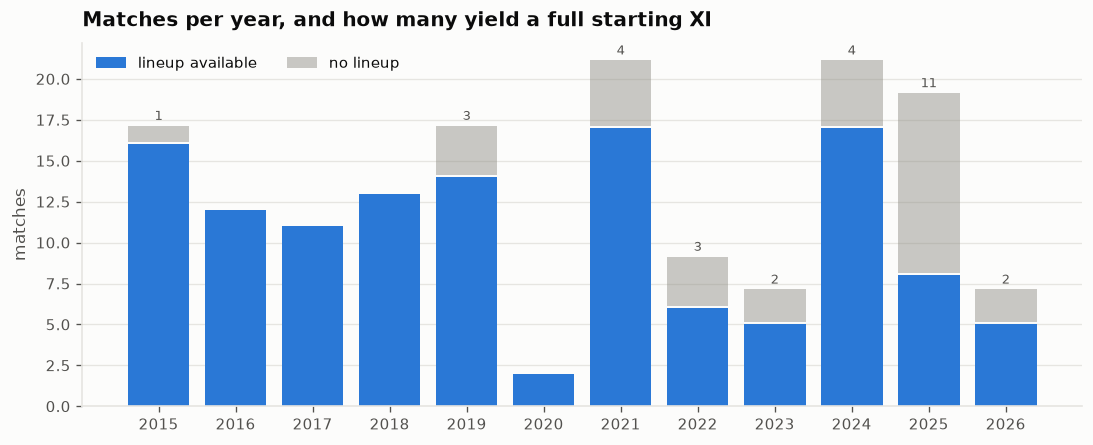

since 2015: 126 of 156 (81%) have a full XI


In [13]:
coverage = pd.read_csv(OUT / "squad" / "match_coverage.csv", parse_dates=["date"])
cov = coverage[coverage.date >= "2015-01-01"].copy()
cov["year"] = cov.date.dt.year
tab = (cov.groupby("year")
          .agg(total=("has_xi", "size"), with_xi=("has_xi", "sum"))
          .assign(missing=lambda d: d.total - d.with_xi))

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(tab.index, tab.with_xi, color=viz.BLUE, label="lineup available", zorder=2)
ax.bar(tab.index, tab.missing, bottom=tab.with_xi + 0.15, color=viz.INK_MUTED,
       alpha=0.45, label="no lineup", zorder=2)
viz.despine(ax)
ax.set_title("Matches per year, and how many yield a full starting XI")
ax.set_ylabel("matches")
ax.set_xticks(tab.index)
ax.legend(loc="upper left", ncols=2)
for yr, r in tab.iterrows():
    if r.missing:
        ax.annotate(f"{int(r.missing)}", xy=(yr, r.total + 0.5), ha="center",
                    fontsize=8, color=viz.INK_2)
plt.show()

print(f"since 2015: {tab.with_xi.sum()} of {tab.total.sum()} "
      f"({tab.with_xi.sum() / tab.total.sum():.0%}) have a full XI")

In [14]:
(cov[~cov.has_xi]
 .groupby(["reason", "tournament"]).size()
 .rename("matches").reset_index()
 .sort_values(["reason", "matches"], ascending=[True, False]))

,reason,tournament,matches
0,competition not tracked by fbref,Arab Cup,10
2,competition not tracked by fbref,WAFF Championship,3
1,competition not tracked by fbref,Jordan International Tournament,2
3,fbref report has no lineup,Friendly,5
4,match absent from fbref,Friendly,10


Advanced stats are a separate and stricter limit. They track **competition, not
time** — available for World Cup and Asian Cup matches, absent from qualifiers,
and absent from friendlies in **every** era. Any shot- or tackle-based measure is
confined to roughly 27 tournament matches, and a competitive-vs-friendly
comparison on those stats is impossible at any point in the record.

---

---

## Summary

Everything this notebook establishes, in one place. Each claim is tagged by how
well the numbers actually support it, because three of them are solid and two
commonly-made ones are not.

findfont: Failed to find font weight semibold, now using 700.


findfont: Failed to find font weight semibold, now using 700.


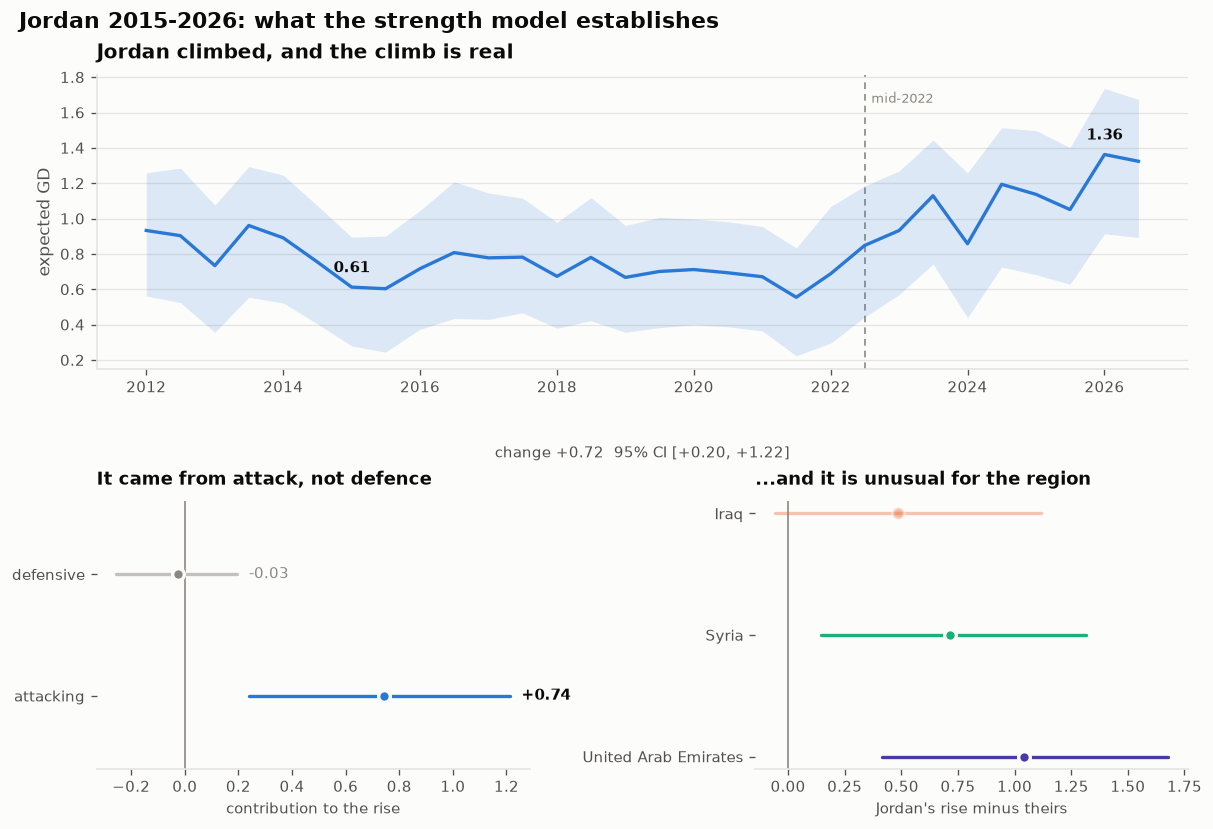

In [15]:
import numpy as np

z = np.load(OUT / "bootstrap_draws.npz", allow_pickle=True)
draws = z["draws"]
tnames = [str(t) for t in z["teams"]]
pnames = [str(p) for p in z["params"]]
bdates = pd.to_datetime(z["dates"], unit="D")
S, A, D = pnames.index("strength"), pnames.index("attack"), pnames.index("defence")
jj = tnames.index("Jordan")
i0 = list(bdates).index(pd.Timestamp("2015-01-01"))
i1 = list(bdates).index(pd.Timestamp("2026-01-01"))

rise      = draws[:, i1, S, jj] - draws[:, i0, S, jj]
atk_part  = np.exp(draws[:, i1, A, jj]) - np.exp(draws[:, i0, A, jj])
def_part  = np.exp(-draws[:, i0, D, jj]) - np.exp(-draws[:, i1, D, jj])

def band(x):
    lo, hi = np.nanpercentile(x, [2.5, 97.5])
    return float(np.nanmean(x)), float(lo), float(hi)

cmp_tbl = pd.read_csv(OUT / "placebo_strength_comparison.csv")
peers = cmp_tbl[cmp_tbl.kind == "rise vs peer"].copy()
peers["label"] = peers.subject.str.replace("Jordan - ", "", regex=False)

fig = plt.figure(figsize=(10, 6.8))
gs = fig.add_gridspec(2, 2, height_ratios=[1.1, 1])

# --- the climb ---------------------------------------------------------
ax = fig.add_subplot(gs[0, :])
ax.fill_between(strength.date, strength.strength_lo, strength.strength_hi,
                color=viz.BLUE, alpha=0.15, linewidth=0)
ax.plot(strength.date, strength.strength, color=viz.BLUE)
viz.mark_split(ax); viz.despine(ax)
ax.set_title("Jordan climbed, and the climb is real")
ax.set_ylabel("expected GD")
for when in ("2015-01-01", "2026-01-01"):
    r = strength.loc[strength.date == when].iloc[0]
    ax.annotate(f"{r.strength:.2f}", xy=(r.date, r.strength), xytext=(0, 9),
                textcoords="offset points", ha="center", fontsize=9,
                color=viz.INK, fontweight="semibold")
mu, lo, hi = band(rise)
ax.annotate(f"change {mu:+.2f}  95% CI [{lo:+.2f}, {hi:+.2f}]",
            xy=(0.5, -0.30), xycoords="axes fraction", ha="center",
            fontsize=9, color=viz.INK_2)

# --- where it came from ------------------------------------------------
ax = fig.add_subplot(gs[1, 0])
parts = [("attacking", atk_part), ("defensive", def_part)]
for i, (name, arr) in enumerate(parts):
    mu, lo, hi = band(arr)
    solid = lo * hi > 0
    colour = viz.BLUE if solid else viz.INK_MUTED
    ax.plot([lo, hi], [i, i], color=colour, linewidth=2, zorder=2,
            alpha=1.0 if solid else 0.5, solid_capstyle="round")
    ax.plot([mu], [i], "o", color=colour, markersize=7, zorder=3,
            markeredgecolor=viz.SURFACE, markeredgewidth=2)
    ax.annotate(f"{mu:+.2f}", xy=(hi, i), xytext=(7, 0), textcoords="offset points",
                va="center", fontsize=9, color=viz.INK if solid else viz.INK_MUTED,
                fontweight="semibold" if solid else "normal")
ax.axvline(0, color=viz.INK_MUTED, linewidth=1.0, zorder=1)
ax.set_yticks([0, 1], ["attacking", "defensive"])
ax.set_ylim(-0.6, 1.6)
viz.despine(ax, keep=("bottom",)); ax.grid(axis="y", visible=False)
ax.set_title("It came from attack, not defence", fontsize=11)
ax.set_xlabel("contribution to the rise", fontsize=9)

# --- and it is unusual -------------------------------------------------
ax = fig.add_subplot(gs[1, 1])
peers = peers.iloc[::-1].reset_index(drop=True)
for i, r in peers.iterrows():
    solid = bool(r.excludes_zero)
    colour = viz.TEAM_COLOURS[r.label]
    ax.plot([r.lo, r.hi], [i, i], color=colour, linewidth=2, zorder=2,
            alpha=1.0 if solid else 0.38, solid_capstyle="round")
    ax.plot([r.estimate], [i], "o", color=colour, markersize=7, zorder=3,
            alpha=1.0 if solid else 0.45,
            markeredgecolor=viz.SURFACE, markeredgewidth=2)
ax.axvline(0, color=viz.INK_MUTED, linewidth=1.0, zorder=1)
ax.set_yticks(range(len(peers)), peers.label, fontsize=9)
viz.despine(ax, keep=("bottom",)); ax.grid(axis="y", visible=False)
ax.set_title("...and it is unusual for the region", fontsize=11)
ax.set_xlabel("Jordan's rise minus theirs", fontsize=9)

fig.suptitle("Jordan 2015-2026: what the strength model establishes",
             fontsize=13, fontweight="semibold", x=0.01, ha="left", color=viz.INK)
plt.show()

### What the strength model establishes

**Jordan improved, and the improvement is real.** +0.717 in expected goal
difference between 2015 and 2026, 95% CI [+0.203, +1.220]. The interval clears
zero, so this is not an artefact of a thin record.

**The improvement is attacking, not defensive.** The attacking contribution is
+0.744 [+0.238, +1.212]; the defensive contribution is −0.027 [−0.255, +0.196]
and cannot be told apart from zero. Their difference, +0.771 [+0.229, +1.282],
is the test that matters, and it clears zero. Jordan scores more relative to its
opponents than it used to; it does not concede measurably less.

**The improvement is unusual for the region.** Of Jordan, Iraq, Syria and UAE,
only Jordan's rise is distinguishable from zero. Jordan's rise beats Syria's
(+0.714 [+0.146, +1.314]) and UAE's (+1.043 [+0.413, +1.679]) outright.

### The one-sentence version

> Between 2015 and 2026 Jordan climbed by about 0.7 goals of expected goal
> difference — a rise its regional peers did not match — and essentially all of
> that came from scoring more rather than conceding less.

### What the next notebook inherits

165 parsed match reports; 126 of 156 matches since 2015 carry a full starting XI
(81%), with the 30 gaps itemised by cause. Lineups, minutes, ages, goals,
substitutions and cards run the whole span. Shots, possession and anything
positional are gated by competition rather than date, so they cannot speak to a
change dated to 2022.

That sets the question for the next notebook: the rise is attacking, so **where
did the extra goals come from** — the same players scoring more, or different
players entirely?

## Where this stops

Everything above is the model, and the data it will be applied to. The composition
analysis — turnover, minutes concentration, age profile, and whether any of it
tracks the strength shift — comes next, in its own notebook, once this one is
agreed.

Two things should be settled before that analysis means much:

1. **The placebo.** Iraq, Palestine, Oman and Bahrain through the same pipeline.
   Without it, no pattern found in Jordan's squad is demonstrably Jordan's.
2. **The Arab Cup gap.** Ten competitive, rotation-heavy fixtures currently
   invisible, concentrated in 2025.